In [1]:
####################################################
####################################################
## test the VAME with SLEAP output 
## original notebook from https://ethoml.github.io/VAME/docs/getting_started/step_by_step
####################################################
####################################################

In [2]:
import vame
from vame.util.sample_data import download_sample_data
from pathlib import Path

2026-11-04 14:09:36.650 INFO  --- [MainThread] numexpr.utils   : 164 : NumExpr defaulting to 10 threads.
2026-11-04 14:09:55.214 INFO  --- [MainThread] vame.util.auxiliary : 45 : Using MPS (Apple Silicon GPU)
2026-11-04 14:09:56.880 INFO  --- [MainThread] vame.util.auxiliary : 45 : Using MPS (Apple Silicon GPU)


In [5]:
# You can run VAME with data from different sources:
# "DeepLabCut", "SLEAP", "LightningPose" or "NWB"
source_software = "SLEAP"

# Download sample data
#sample = download_sample_data(source_software)
videos = ["/Volumes/groups/tanaka/People/current/jiwang/projects/image_analysis/Deniz_video_sleap/sleap_test/videos/labels.v003_245frames.labeled_trained.mp4"]
poses_estimations = ["/Volumes/groups/tanaka/People/current/jiwang/projects/image_analysis/Deniz_video_sleap/sleap_test/labels.v003_245frames.labeled_trained.slp"]
fps = 30

print(videos)
print(poses_estimations)
print(fps)

['/Volumes/groups/tanaka/People/current/jiwang/projects/image_analysis/Deniz_video_sleap/sleap_test/videos/labels.v003_245frames.labeled_trained.mp4']
['/Volumes/groups/tanaka/People/current/jiwang/projects/image_analysis/Deniz_video_sleap/sleap_test/labels.v003_245frames.labeled_trained.slp']
30


In [9]:
outDir = "/Volumes/groups/tanaka/People/current/jiwang/projects/image_analysis/Deniz_video_sleap/sleap_test/vame_test"

In [30]:
config_file, config_data = vame.init_new_project(
    project_name="my_vame_sleap",
    poses_estimations=poses_estimations,
    source_software="SLEAP",
    fps=fps,
)

2026-11-04 15:19:18.889 INFO  --- [MainThread] vame.initialize_project.new : 100 : Project "/Users/jingkui.wang/workspace/imp/image_analysis_test/scripts/my_vame_sleap" already exists!


In [7]:
print(config_data)

{'vame_version': '0.15.0', 'project_name': 'my_vame_sleap', 'project_path': '/Users/jingkui.wang/workspace/imp/image_analysis_test/scripts/my_vame_sleap', 'creation_datetime': '2026-11-04T13:16:20+00:00', 'session_names': ['labels.v003_245frames.labeled_trained'], 'project_random_state': 42, 'all_data': 'yes', 'keypoints': ['nose', 'eyeL', 'eyeR', 'head', 'torso', 'tail_base', 'tail_2', 'tail_3', 'tail_tip'], 'egocentric_data': False, 'pose_confidence': 0.99, 'robust': True, 'iqr_factor': 4, 'savgol_filter': True, 'savgol_length': 5, 'savgol_order': 2, 'test_fraction': 0.1, 'model_name': 'VAME', 'pretrained_model': 'None', 'pretrained_weights': False, 'num_features': 18, 'batch_size': 256, 'max_epochs': 500, 'model_snapshot': 50, 'model_convergence': 50, 'transition_function': 'GRU', 'beta': 1, 'beta_norm': False, 'zdims': 30, 'learning_rate': 0.0005, 'time_window': 30, 'prediction_decoder': 1, 'prediction_steps': 15, 'noise': False, 'scheduler': 1, 'scheduler_step_size': 100, 'schedul

In [8]:
ds_path = Path(config_data["project_path"]) / "data" / "raw" / f"{config_data['session_names'][0]}.nc"
vame.io.load_poses.load_vame_dataset(ds_path)

<xarray.Dataset> Size: 439kB
Dimensions:      (time: 3784, space: 2, keypoints: 9, individuals: 1)
Coordinates:
  * time         (time) float64 30kB 0.0 0.03333 0.06667 ... 126.0 126.1 126.1
  * space        (space) <U1 8B 'x' 'y'
  * keypoints    (keypoints) <U9 324B 'nose' 'eyeL' ... 'tail_3' 'tail_tip'
  * individuals  (individuals) <U4 16B 'id_0'
Data variables:
    position     (time, space, keypoints, individuals) float32 272kB 200.8 .....
    confidence   (time, keypoints, individuals) float32 136kB nan nan ... nan
Attributes:
    source_software:  SLEAP
    ds_type:          poses
    fps:              30.0
    time_unit:        seconds
    source_file:      /Volumes/groups/tanaka/People/current/jiwang/projects/i...

In [10]:
## Step 2: Preprocess the raw pose estimation data
vame.preprocessing(
    config=config_data,
    centered_reference_keypoint="torso",
    orientation_reference_keypoint="tail_base",
)

2026-11-04 14:19:47.925 INFO  --- [MainThread] vame.preprocessing.preprocessing : 90 : Cleaning low confidence data points. Confidence threshold: 0.99
2026-11-04 14:19:47.926 INFO  --- [MainThread] vame.preprocessing.preprocessing : 105 : Egocentrically aligning and centering with references: torso and tail_base
2026-11-04 14:19:47.926 INFO  --- [MainThread] vame.preprocessing.preprocessing : 124 : Cleaning outliers using IQR method...
2026-11-04 14:19:47.927 INFO  --- [MainThread] vame.preprocessing.preprocessing : 140 : Applying Savitzky-Golay filter...
2026-11-04 14:19:47.928 INFO  --- [MainThread] vame.preprocessing.preprocessing : 156 : Rescaling...
2026-11-04 14:19:47.929 INFO  --- [MainThread] vame.preprocessing.preprocessing : 171 : Session: labels.v003_245frames.labeled_trained


'position_scaled'

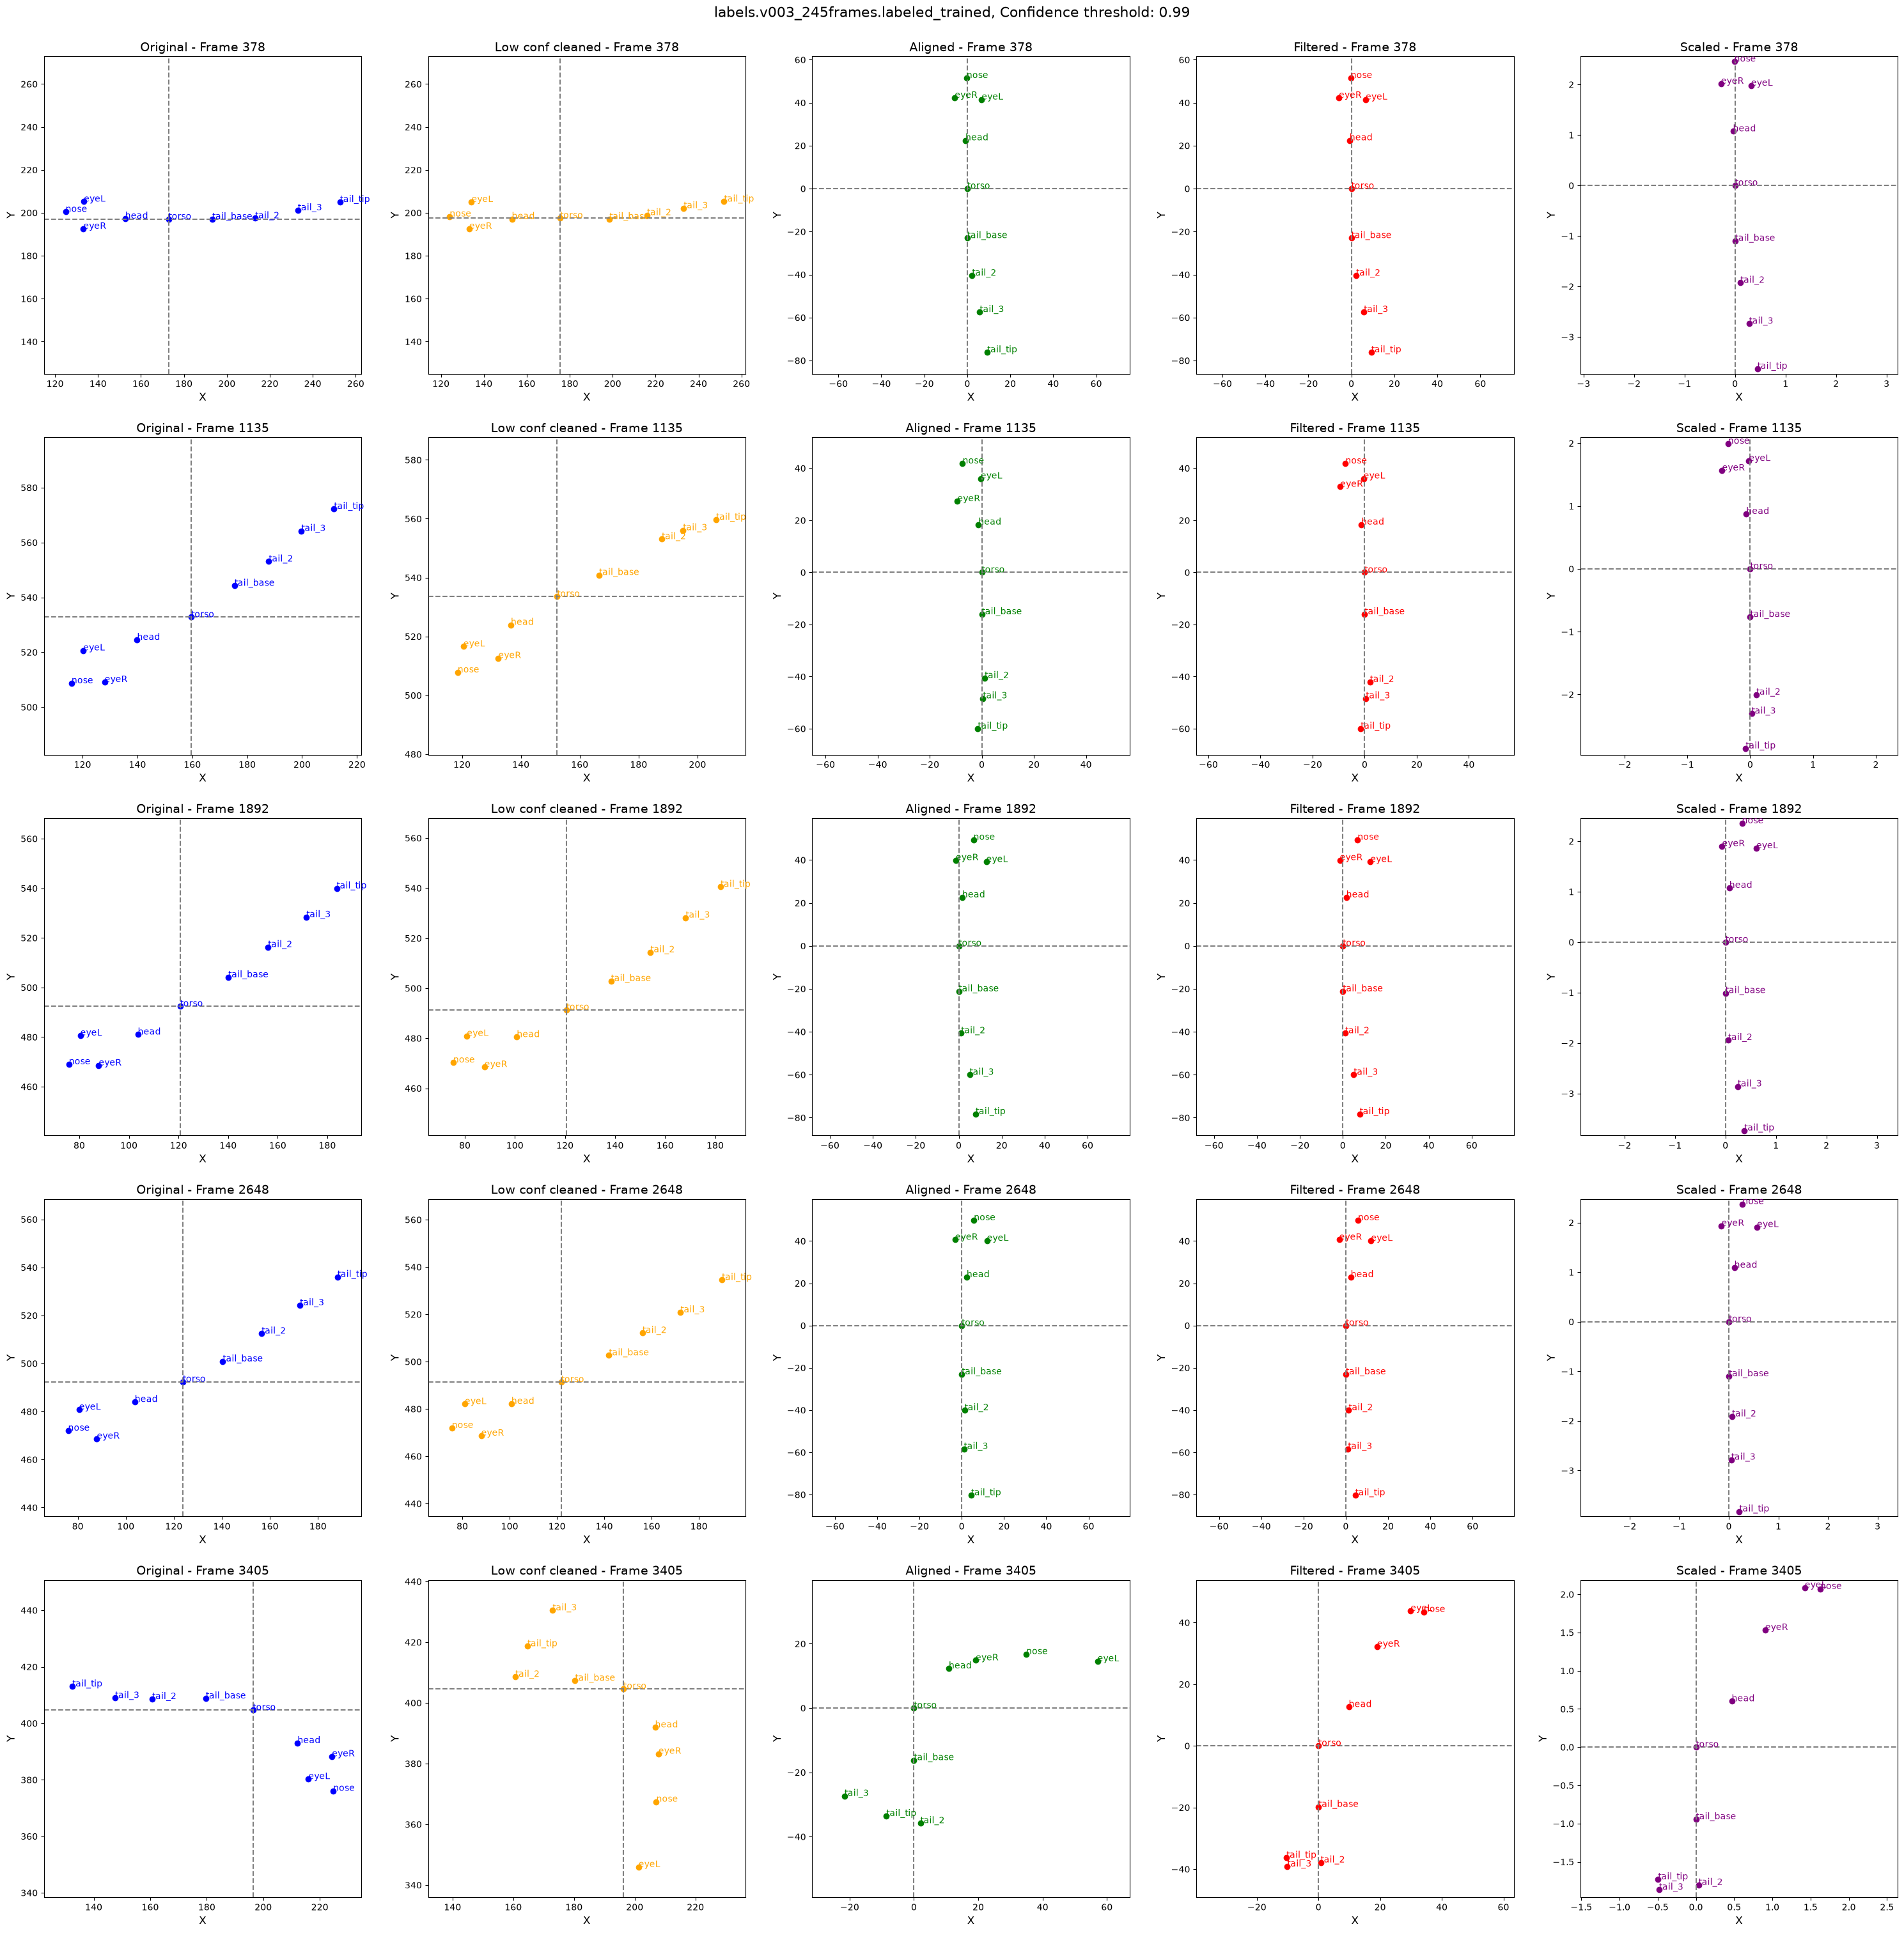

In [122]:
from vame.visualization import visualize_preprocessing_scatter

visualize_preprocessing_scatter(config=config_data)

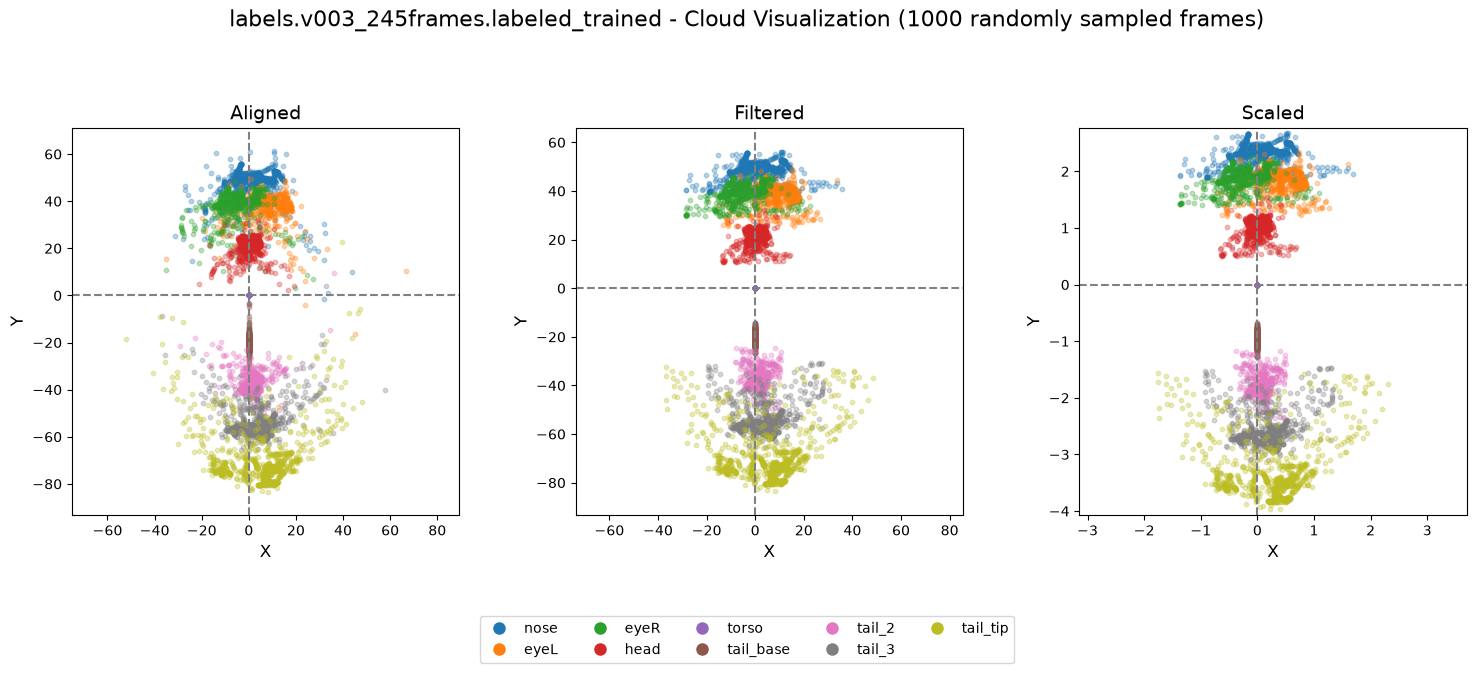

In [127]:
from vame.visualization import visualize_preprocessing_cloud

visualize_preprocessing_cloud(config=config_data)

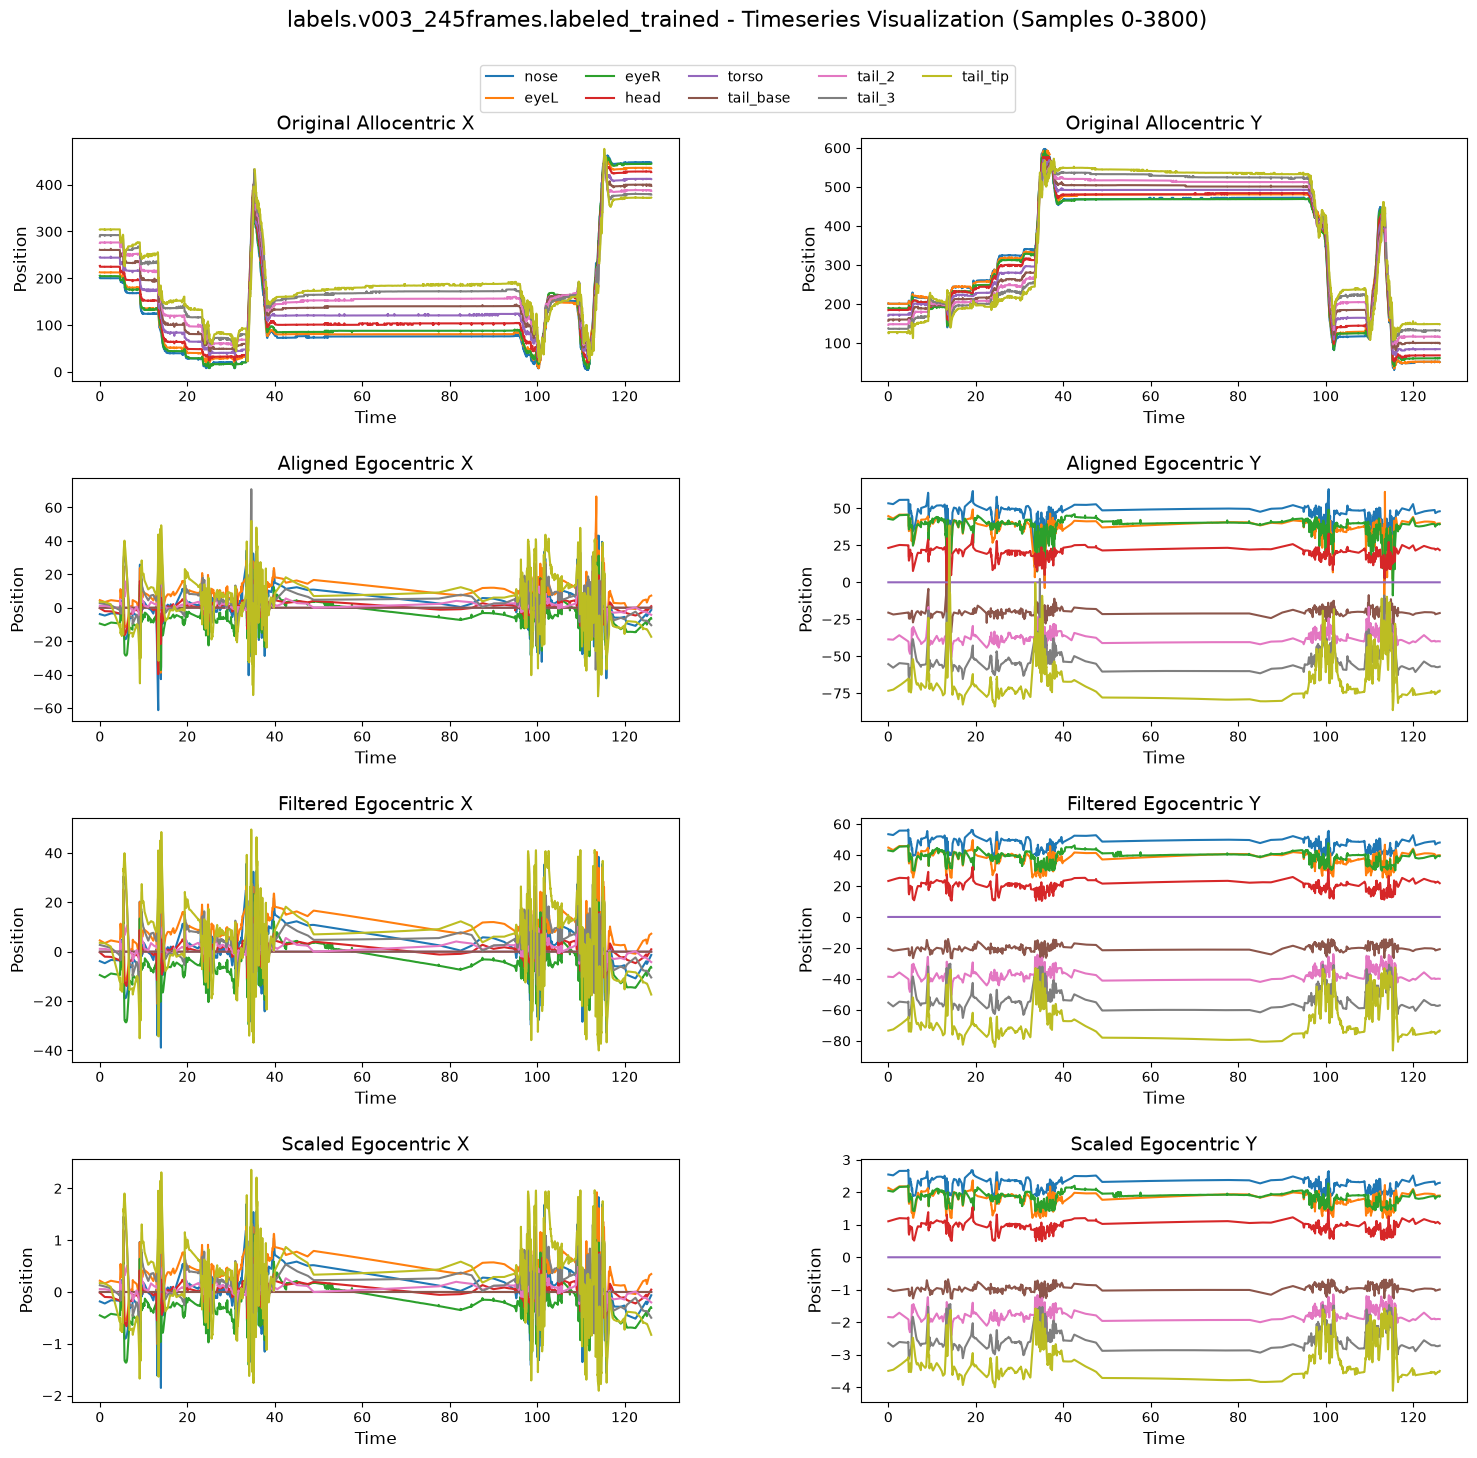

In [128]:
from vame.visualization import visualize_preprocessing_timeseries

visualize_preprocessing_timeseries(config=config_data, n_samples = 3800)

In [11]:
## Step 3: Train the VAME model
vame.create_trainset(
    config=config_data,
    keypoints_to_exclude= None,
)

2026-11-04 14:21:26.576 INFO  --- [MainThread] vame.model.create_training : 339 : Creating training dataset...
2026-11-04 14:21:26.577 INFO  --- [MainThread] vame.model.create_training : 58 : Reading training data from variable: position_scaled
2026-11-04 14:21:26.613 INFO  --- [MainThread] vame.model.create_training : 201 : Session labels.v003_245frames.labeled_trained: test chunk 3174:3552 (length 378)
2026-11-04 14:21:26.618 INFO  --- [MainThread] vame.model.create_training : 222 : Normalization: mean -0.0578, std 1.5992
2026-11-04 14:21:26.619 INFO  --- [MainThread] vame.model.create_training : 252 : Metadata file saved for feature provenance tracking
2026-11-04 14:21:26.620 INFO  --- [MainThread] vame.model.create_training : 253 : Metadata: /Users/jingkui.wang/workspace/imp/image_analysis_test/scripts/my_vame_sleap/data/train/metadata.json
2026-11-04 14:21:26.620 INFO  --- [MainThread] vame.model.create_training : 255 : Length of train data: 3406
2026-11-04 14:21:26.620 INFO  --- 

In [12]:
# train the VAME model. This migth take a while, depending on dataset size and your hardware
vame.train_model(config=config_data)

2026-11-04 14:21:38.575 INFO  --- [MainThread] vame.model.rnn_vae : 645 : Train Variational Autoencoder - model name: VAME 

2026-11-04 14:21:38.616 INFO  --- [MainThread] vame.model.rnn_vae : 656 : TensorBoard logging enabled. Log directory: /Users/jingkui.wang/workspace/imp/image_analysis_test/scripts/my_vame_sleap/logs/tensorboard/VAME
2026-11-04 14:21:38.617 INFO  --- [MainThread] vame.model.rnn_vae : 657 : To view logs, run: tensorboard --logdir=/Users/jingkui.wang/workspace/imp/image_analysis_test/scripts/my_vame_sleap/logs/tensorboard --port=6006
2026-11-04 14:21:38.618 INFO  --- [MainThread] vame.util.auxiliary : 45 : Using MPS (Apple Silicon GPU)
2026-11-04 14:21:38.618 INFO  --- [MainThread] vame.model.rnn_vae : 703 : Latent Dimensions: 30, Time window: 30, Batch Size: 256, Beta: 1, lr: 0.0005

2026-11-04 14:21:38.706 | WARNING  | torch.jit._trace:trace:1006 - /Users/jingkui.wang/miniforge3/envs/keypoint_moseq/lib/python3.12/site-packages/torch/jit/_trace.py:1006: FutureWarni

In [13]:
vame.evaluate_model(config=config_data)

2026-11-04 14:26:21.336 INFO  --- [MainThread] vame.model.evaluate : 273 : Evaluation of model: VAME
2026-11-04 14:26:21.454 INFO  --- [MainThread] vame.model.evaluate : 97 : Initialize test data. Datapoints 378
2026-11-04 14:26:21.973 INFO  --- [MainThread] vame.model.evaluate : 293 : Evaluation finished successfully! You can find the results in: '/Users/jingkui.wang/workspace/imp/image_analysis_test/scripts/my_vame_sleap/model/evaluate/'
2026-11-04 14:26:21.974 INFO  --- [MainThread] vame.model.evaluate : 294 : Next steps:
            - vame.segment_session() to identify behavioral motifs.
            - re-run the model for further fine tuning. Check again with vame.evaluate_model()


In [ ]:
from vame.visualization import plot_loss

plot_loss(config=config_data)
from IPython.display import Image, display

In [ ]:
eval_plot_path = Path(config_data["project_path"]) / "model" / "evaluate" / "future_reconstruction.png"
display(Image(filename=eval_plot_path))

In [160]:
config_data['n_clusters'] = 5
config_data

{'vame_version': '0.15.0', 'project_name': 'my_vame_sleap', 'project_path': '/Users/jingkui.wang/workspace/imp/image_analysis_test/scripts/my_vame_sleap', 'creation_datetime': '2026-11-04T13:16:20+00:00', 'session_names': ['labels.v003_245frames.labeled_trained'], 'project_random_state': 42, 'all_data': 'yes', 'keypoints': ['nose', 'eyeL', 'eyeR', 'head', 'torso', 'tail_base', 'tail_2', 'tail_3', 'tail_tip'], 'egocentric_data': False, 'pose_confidence': 0.99, 'robust': True, 'iqr_factor': 4, 'savgol_filter': True, 'savgol_length': 5, 'savgol_order': 2, 'test_fraction': 0.1, 'model_name': 'VAME', 'pretrained_model': 'None', 'pretrained_weights': False, 'num_features': 15, 'batch_size': 256, 'max_epochs': 500, 'model_snapshot': 50, 'model_convergence': 50, 'transition_function': 'GRU', 'beta': 1, 'beta_norm': False, 'zdims': 30, 'learning_rate': 0.0005, 'time_window': 30, 'prediction_decoder': 1, 'prediction_steps': 15, 'noise': False, 'scheduler': 1, 'scheduler_step_size': 100, 'schedul

In [161]:
## Step 4: Segment behavior
vame.segment_session(
    config=config_data,
    overwrite_segmentation=False,
    overwrite_embeddings=False,
)

2026-11-06 15:52:14.237 INFO  --- [MainThread] vame.analysis.pose_segmentation : 89 : ---------------------------------------------------------------------
2026-11-06 15:52:14.238 INFO  --- [MainThread] vame.analysis.pose_segmentation : 90 : Embedding latent vectors for VAME model
2026-11-06 15:52:14.251 INFO  --- [MainThread] vame.util.model_util : 56 : Loaded training metadata with 9 keypoints
2026-11-06 15:52:14.252 INFO  --- [MainThread] vame.util.model_util : 57 : Keypoints used during training: ['nose', 'eyeL', 'eyeR', 'head', 'torso', 'tail_base', 'tail_2', 'tail_3', 'tail_tip']
2026-11-06 15:52:14.252 INFO  --- [MainThread] vame.analysis.pose_segmentation : 105 : Reading model input from variable: position_scaled
2026-11-06 15:52:14.265 INFO  --- [MainThread] vame.analysis.pose_segmentation : 124 : Latent vector for labels.v003_245frames.labeled_trained already exists, skipping...
2026-11-06 15:52:14.271 INFO  --- [MainThread] vame.analysis.pose_segmentation : 706 : -----------

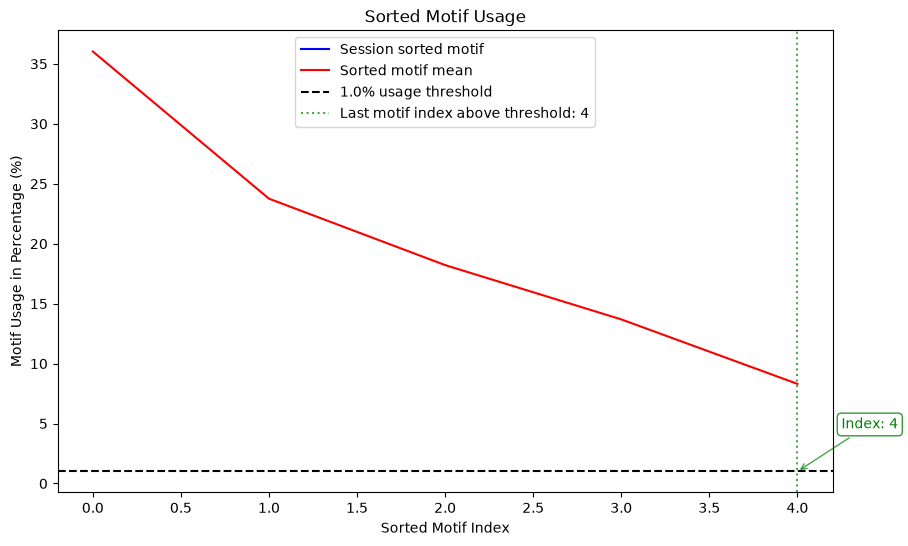

In [163]:
from vame.visualization import visualize_motif_thresholding

visualize_motif_thresholding(
    config=config_data,
    segmentation_algorithm="hmm",
    threshold=1.0,
)

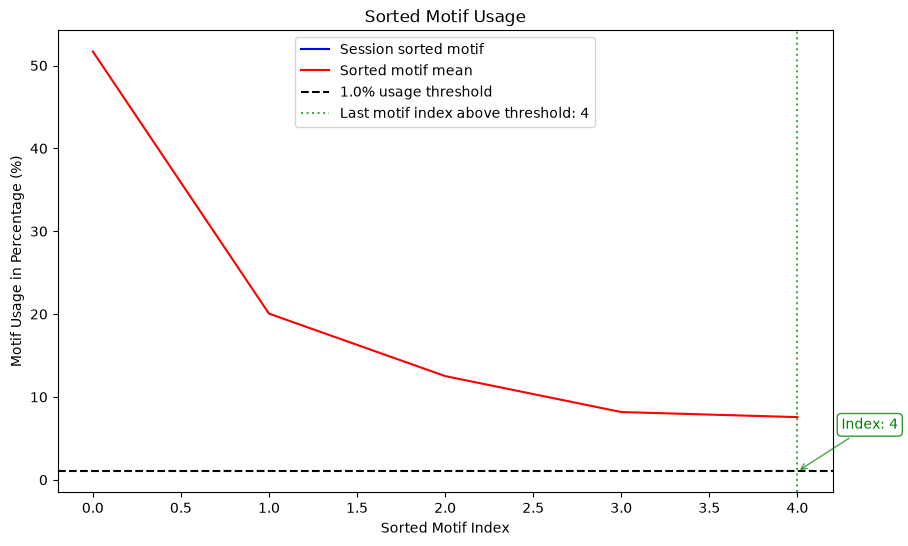

In [164]:
visualize_motif_thresholding(
    config=config_data,
    segmentation_algorithm="kmeans",
    threshold=1.0,
)

In [165]:
vame.community(
    config=config_data,
    cut_tree=3,
)

2026-11-06 15:52:40.790 INFO  --- [MainThread] vame.analysis.community_analysis : 497 : ---------------------------------------------------------------------
2026-11-06 15:52:40.791 INFO  --- [MainThread] vame.analysis.community_analysis : 498 : Community analysis for model: VAME 

2026-11-06 15:52:40.792 INFO  --- [MainThread] vame.analysis.community_analysis : 500 : Community analysis for segmentation algorithm hmm with 5 clusters
2026-11-06 15:52:40.799 INFO  --- [MainThread] vame.analysis.community_analysis : 527 : Cohort motif labels from hmm saved
2026-11-06 15:52:40.802 INFO  --- [MainThread] vame.analysis.community_analysis : 535 : Cohort motif counts from hmm saved
2026-11-06 15:52:40.803 INFO  --- [MainThread] vame.analysis.community_analysis : 536 : [ 684.  892.  514.  312. 1353.]
2026-11-06 15:52:40.809 INFO  --- [MainThread] vame.analysis.community_analysis : 550 : Cohort transition matrix saved
2026-11-06 15:52:40.809 | WARNING  | vame.analysis.tree_hierarchy:merge_func:4

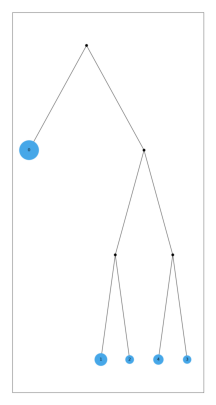

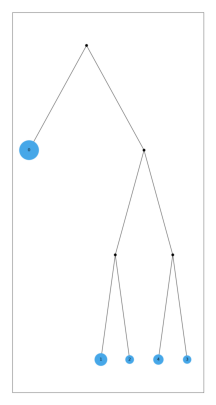

In [166]:
from vame.visualization import visualize_hierarchical_tree

visualize_hierarchical_tree(
    config=config_data,
    segmentation_algorithm="kmeans",
    
) 

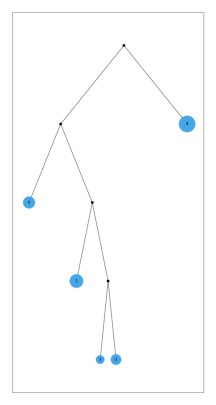

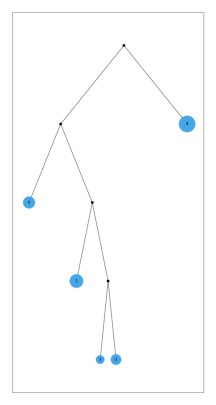

In [167]:
from vame.visualization import visualize_hierarchical_tree

visualize_hierarchical_tree(
    config=config_data,
    segmentation_algorithm="hmm",
    
) 

In [268]:
config_data = vame.update_config(
    config=config_data,
    config_update={
        "n_neighbors": 500,
        "min_dist": 0.7,
    },
)
print(config_data)

{'vame_version': '0.15.0', 'project_name': 'my_vame_sleap', 'project_path': '/Users/jingkui.wang/workspace/imp/image_analysis_test/scripts/my_vame_sleap', 'creation_datetime': '2026-11-04T13:16:20+00:00', 'session_names': ['labels.v003_245frames.labeled_trained'], 'project_random_state': 42, 'all_data': 'yes', 'keypoints': ['nose', 'eyeL', 'eyeR', 'head', 'torso', 'tail_base', 'tail_2', 'tail_3', 'tail_tip'], 'egocentric_data': False, 'pose_confidence': 0.99, 'robust': True, 'iqr_factor': 4, 'savgol_filter': True, 'savgol_length': 5, 'savgol_order': 2, 'test_fraction': 0.1, 'model_name': 'VAME', 'pretrained_model': 'None', 'pretrained_weights': False, 'num_features': 15, 'batch_size': 256, 'max_epochs': 500, 'model_snapshot': 50, 'model_convergence': 50, 'transition_function': 'GRU', 'beta': 1, 'beta_norm': False, 'zdims': 30, 'learning_rate': 0.0005, 'time_window': 30, 'prediction_decoder': 1, 'prediction_steps': 15, 'noise': False, 'scheduler': 1, 'scheduler_step_size': 100, 'schedul

2026-11-09 12:17:10.927 INFO  --- [MainThread] vame.visualization.umap : 646 : Computing UMAP embeddings for all sessions combined...
2026-11-09 12:17:10.931 INFO  --- [MainThread] vame.visualization.umap : 75 : Running UMAP calculation...
2026-11-09 12:17:10.933 | WARNING  | umap.umap_:_validate_parameters:1952 - /Users/jingkui.wang/miniforge3/envs/keypoint_moseq/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(



Previous UMAP backed up to: /Users/jingkui.wang/workspace/imp/image_analysis_test/scripts/my_vame_sleap/results/umap_embedding_backup_20261109_121710_912025.nc


2026-11-09 12:17:25.272 INFO  --- [MainThread] vame.visualization.umap : 169 : UMAP embeddings saved to /Users/jingkui.wang/workspace/imp/image_analysis_test/scripts/my_vame_sleap/results/umap_embedding.nc
2026-11-09 12:17:25.324 INFO  --- [MainThread] vame.visualization.umap : 711 : UMAP figure saved to /Users/jingkui.wang/workspace/imp/image_analysis_test/scripts/my_vame_sleap/reports/umap/umap_VAME_hmm-5.png
2026-11-09 12:17:25.408 INFO  --- [MainThread] vame.visualization.umap : 711 : UMAP figure saved to /Users/jingkui.wang/workspace/imp/image_analysis_test/scripts/my_vame_sleap/reports/umap/umap_VAME_hmm-5_motif.png
2026-11-09 12:17:25.493 INFO  --- [MainThread] vame.visualization.umap : 711 : UMAP figure saved to /Users/jingkui.wang/workspace/imp/image_analysis_test/scripts/my_vame_sleap/reports/umap/umap_VAME_hmm-5_community.png
2026-11-09 12:17:25.545 INFO  --- [MainThread] vame.visualization.umap : 711 : UMAP figure saved to /Users/jingkui.wang/workspace/imp/image_analysis_te

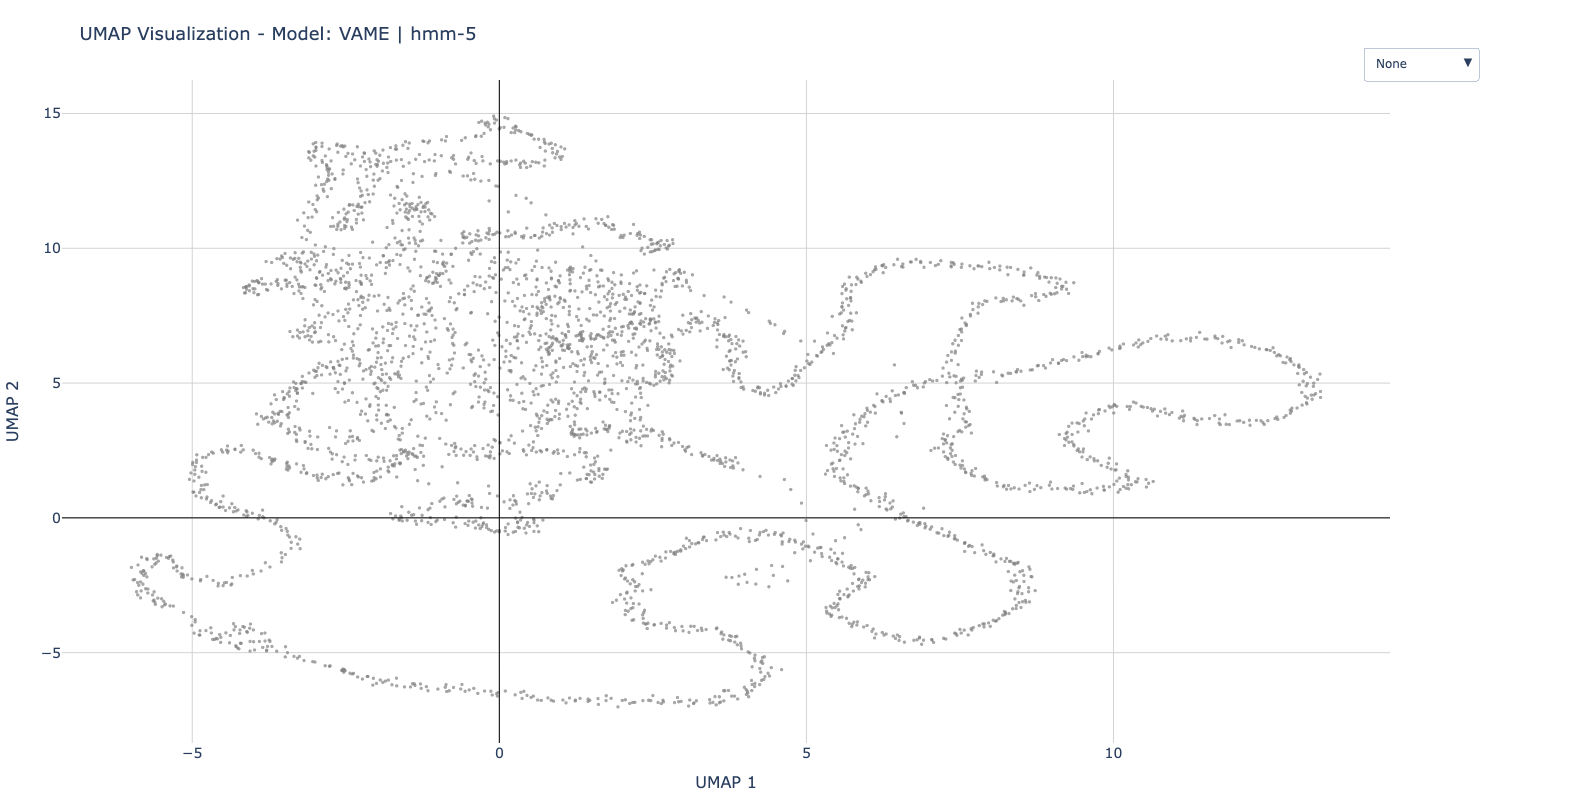

2026-11-09 12:17:26.408 INFO  --- [MainThread] vame.visualization.umap : 742 : Interactive UMAP figure saved to /Users/jingkui.wang/workspace/imp/image_analysis_test/scripts/my_vame_sleap/reports/umap/umap_VAME_kmeans-5_interactive.html


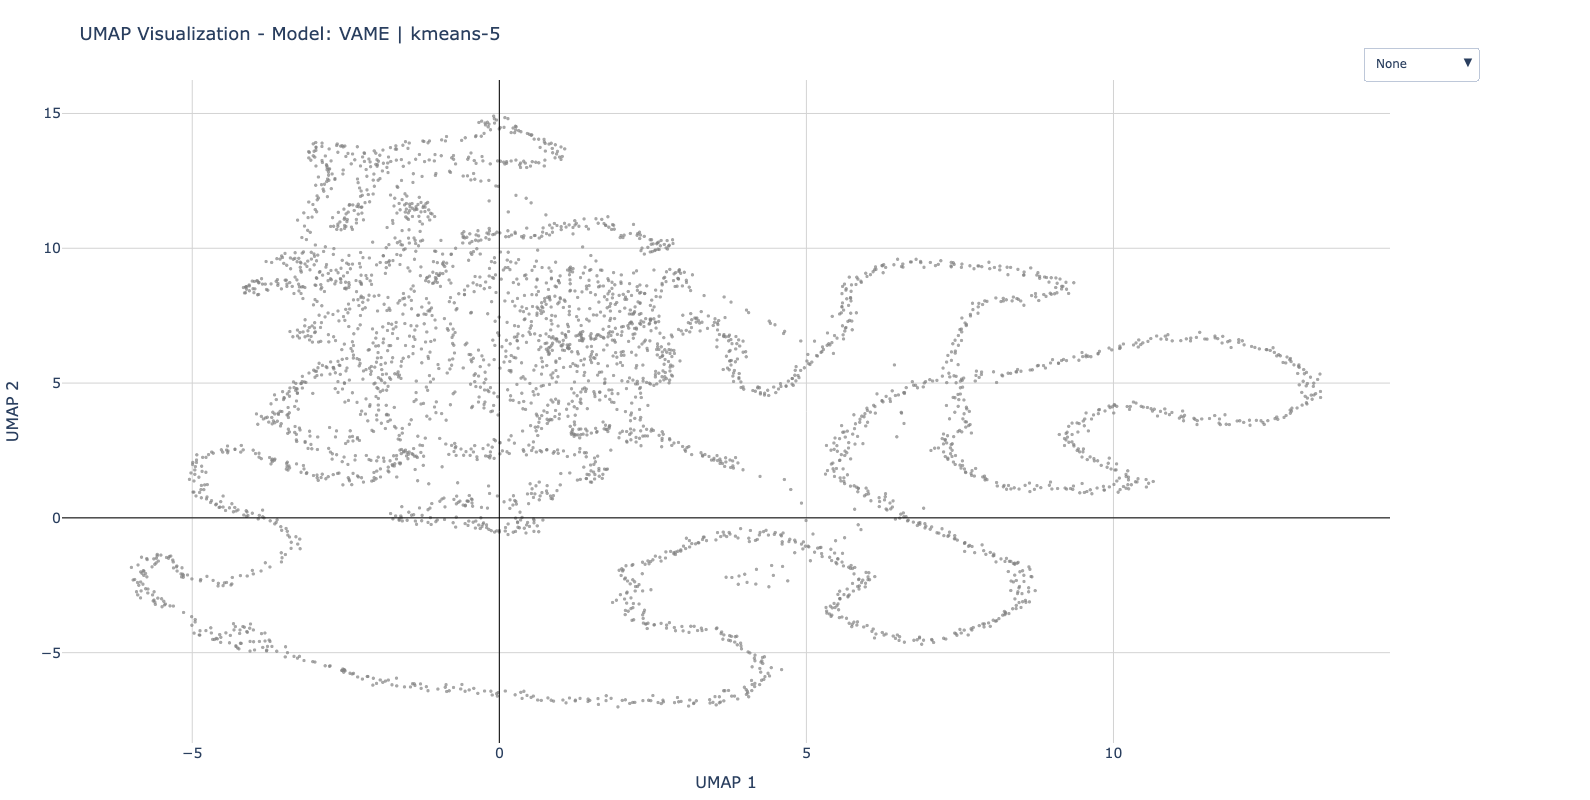

In [269]:
## Uncomment  the lines below if you can't see the plotly figures in the Jupyter Notebook
# import plotly.io as pio
# pio.renderers.default = 'iframe'
from pathlib import Path
from datetime import datetime
from vame.visualization import visualize_umap
cache = Path(config_data["project_path"]) / "results" / "umap_embedding.nc"

if cache.exists():
    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    backup = cache.with_name(f"umap_embedding_backup_{timestamp}.nc")
    cache.rename(backup)
    print(f"Previous UMAP backed up to: {backup}")
else:
    print(f"No cache found at: {cache}")
    
visualize_umap(
    config=config_data,
    show_figure="plotly",
    
)

In [170]:
## Create motif and community videos
from vame.video import add_videos_to_project

add_videos_to_project(config=config_data, videos=videos)

2026-11-06 15:53:03.671 INFO  --- [MainThread] vame.video.video : 165 : Creating symbolic link from /Volumes/groups/tanaka/People/current/jiwang/projects/image_analysis/Deniz_video_sleap/sleap_test/videos/labels.v003_245frames.labeled_trained.mp4 to /Users/jingkui.wang/workspace/imp/image_analysis_test/scripts/my_vame_sleap/data/raw/labels.v003_245frames.labeled_trained.mp4


OSError: Failed to create a symbolic link from /Volumes/groups/tanaka/People/current/jiwang/projects/image_analysis/Deniz_video_sleap/sleap_test/videos/labels.v003_245frames.labeled_trained.mp4 to /Users/jingkui.wang/workspace/imp/image_analysis_test/scripts/my_vame_sleap/data/raw/labels.v003_245frames.labeled_trained.mp4. On Windows, symlinks require Administrator privileges or Developer Mode. Enable Developer Mode in Windows Settings, run as Administrator, or pass copy_videos=True to copy the files instead.

In [171]:
vame.motif_videos(config=config_data)

2026-11-06 15:53:04.838 INFO  --- [MainThread] vame.analysis.videowriter : 217 : Creating motif videos for session labels.v003_245frames.labeled_trained, algorithm: hmm, n_clusters: 5
2026-11-06 15:53:04.840 INFO  --- [MainThread] vame.analysis.videowriter : 73 : Motif videos getting created for labels.v003_245frames.labeled_trained ...
2026-11-06 15:53:04.863 INFO  --- [MainThread] vame.analysis.videowriter : 83 : 0%|          | 0/3770 [00:00<?, ?it/s]
2026-11-06 15:53:05.6 INFO  --- [MainThread] vame.analysis.videowriter : 83 : 0%|          | 16/3770 [00:00<00:33, 112.93it/s]
2026-11-06 15:53:05.106 INFO  --- [MainThread] vame.analysis.videowriter : 83 : 3%|2         | 111/3770 [00:00<00:06, 531.44it/s]
2026-11-06 15:53:05.322 INFO  --- [MainThread] vame.analysis.videowriter : 83 : 5%|4         | 172/3770 [00:00<00:09, 380.23it/s]
2026-11-06 15:53:05.439 INFO  --- [MainThread] vame.analysis.videowriter : 83 : 6%|5         | 218/3770 [00:00<00:09, 384.96it/s]
2026-11-06 15:53:05.539 I

In [172]:
vame.community_videos(config=config_data)

2026-11-06 15:53:12.610 INFO  --- [MainThread] vame.analysis.videowriter : 301 : Creating community videos for session labels.v003_245frames.labeled_trained, algorithm: hmm, n_clusters: 5
2026-11-06 15:53:12.610 INFO  --- [MainThread] vame.analysis.videowriter : 81 : Community videos getting created for labels.v003_245frames.labeled_trained ...
2026-11-06 15:53:12.616 INFO  --- [MainThread] vame.analysis.videowriter : 83 : 0%|          | 0/3770 [00:00<?, ?it/s]
2026-11-06 15:53:12.717 INFO  --- [MainThread] vame.analysis.videowriter : 83 : 1%|          | 24/3770 [00:00<00:15, 238.70it/s]
2026-11-06 15:53:12.896 INFO  --- [MainThread] vame.analysis.videowriter : 83 : 3%|3         | 126/3770 [00:00<00:07, 476.71it/s]
2026-11-06 15:53:13.53 INFO  --- [MainThread] vame.analysis.videowriter : 83 : 6%|5         | 217/3770 [00:00<00:06, 524.68it/s]
2026-11-06 15:53:13.153 INFO  --- [MainThread] vame.analysis.videowriter : 83 : 9%|8         | 325/3770 [00:00<00:04, 691.67it/s]
2026-11-06 15:53

In [173]:
import numpy as np
motifs_hmm = np.load('/Users/jingkui.wang/workspace/imp/image_analysis_test/scripts/my_vame_sleap/results/labels.v003_245frames.labeled_trained/VAME/hmm-5/5_hmm_label_labels.v003_245frames.labeled_trained.npy')

In [174]:
motifs_kmeans = np.load('/Users/jingkui.wang/workspace/imp/image_analysis_test/scripts/my_vame_sleap/results/labels.v003_245frames.labeled_trained/VAME/kmeans-5/5_kmeans_label_labels.v003_245frames.labeled_trained.npy')

In [175]:
motifs = motifs_kmeans

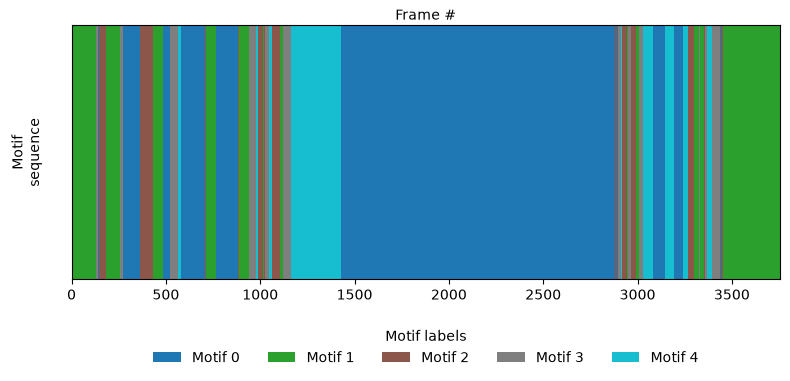

In [176]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm
from matplotlib.patches import Patch
from matplotlib.colors import ListedColormap

# Example: replace this with your own 1D array of motif labels
#motifs = np.array([0, 0, 1, 1, 1, 2, 2, 0, 0, 1, 2, 2])

# Map motif labels to consecutive color indices
labels, color_indices = np.unique(motifs, return_inverse=True)
n_motifs = len(labels)

#cmap = plt.get_cmap("viridis", n_motifs)
cmap = plt.get_cmap("tab10", n_motifs)

#highlight = [4]  # Use [1] to highlight only motif 1
#colors = [
#    cmap(norm(i)) if label in highlight else "lightgray"
#    for i, label in enumerate(labels)
#]
#cmap = ListedColormap(colors)

norm = BoundaryNorm(np.arange(n_motifs + 1) - 0.5, n_motifs)

fig, ax = plt.subplots(figsize=(8, 4))

ax.imshow(
    color_indices[np.newaxis, :],  # shape: (1, number of frames)
    aspect="auto",
    interpolation="nearest",
    cmap=cmap,
    norm=norm,
    extent=(0, len(motifs), 0, 1),
)

ax.set_yticks([])
ax.set_ylabel("Motif\nsequence", rotation=90, labelpad=20)

# Put the frame axis on top, like your example
ax.set_xlabel("Frame #")
ax.xaxis.set_label_position("top")
ax.xaxis.tick_bottom()

handles = [
    Patch(facecolor=cmap(norm(i)), label=f"Motif {label}")
    for i, label in enumerate(labels)
]

ax.legend(
    handles=handles,
    title="Motif labels",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.15),
    ncol=min(6, len(labels)),
    frameon=False,
)

plt.tight_layout()
plt.show()

In [ ]:
##################################################################
## test the wavelet analysis on the aligned egocentric time series
## an example code from https://www.kaggle.com/code/asauve/a-gentle-introduction-to-wavelet-for-data-analysis
##################################################################

In [206]:
import xarray as xr
import pandas as pd
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
import matplotlib.pyplot as plt


In [205]:

ds = xr.open_dataset("/Users/jingkui.wang/workspace/imp/image_analysis_test/scripts/my_vame_sleap/data/processed/labels.v003_245frames.labeled_trained_processed.nc")

print(ds)                    # all variables, dimensions, coordinates and attributes
print(list(ds.data_vars))    # variable names
print(dict(ds.sizes))        # dimension sizes, e.g. time, keypoints, space
print(ds.attrs)              # file-level metadata


<xarray.Dataset> Size: 2MB
Dimensions:                      (time: 3784, space: 2, keypoints: 9,
                                  individuals: 1)
Coordinates:
  * time                         (time) float64 30kB 0.0 0.03333 ... 126.1 126.1
  * space                        (space) <U1 8B 'x' 'y'
  * keypoints                    (keypoints) <U9 324B 'nose' ... 'tail_tip'
  * individuals                  (individuals) <U4 16B 'id_0'
Data variables:
    position                     (time, space, keypoints, individuals) float32 272kB ...
    confidence                   (time, keypoints, individuals) float32 136kB ...
    position_cleaned_lowconf     (time, space, keypoints, individuals) float32 272kB ...
    percentage_low_confidence    (space, keypoints, individuals) float64 144B ...
    individual_scale             (individuals) float64 8B ...
    position_egocentric_aligned  (time, space, keypoints, individuals) float32 272kB ...
    position_processed           (time, space, keypoints

In [190]:
print(list(ds.data_vars)) 

['position', 'confidence', 'position_cleaned_lowconf', 'percentage_low_confidence', 'individual_scale', 'position_egocentric_aligned', 'position_processed', 'percentage_iqr_outliers', 'position_scaled']


In [191]:
var = ds["position_scaled"]   # pick a name from list(ds.data_vars)
print(var.dims, var.shape)

arr = var.values                          # plain NumPy array


('time', 'space', 'keypoints', 'individuals') (3784, 2, 9, 1)


In [193]:
#print(arr)
df = var.to_dataframe().reset_index()   # one column per dimension, plus a value column
#df.to_csv("exported.csv", index=False)
#print(df.head())
df

In [250]:
# Replace the dimension name and label with the ones you saw in print(ds)
snout = ds["position_scaled"].sel(keypoints="nose", individuals="id_0")   # dims: (time, space)

In [251]:
print(snout)

<xarray.DataArray 'position_scaled' (time: 3784, space: 2)> Size: 30kB
[7568 values with dtype=float32]
Coordinates:
  * time         (time) float64 30kB 0.0 0.03333 0.06667 ... 126.0 126.1 126.1
  * space        (space) <U1 8B 'x' 'y'
    keypoints    <U9 36B 'nose'
    individuals  <U4 16B 'id_0'


In [252]:
df_x = pd.DataFrame({
    "time": snout["time"].values,
    "position": snout.sel(space="x").values,
})

df_y = pd.DataFrame({
    "time": snout["time"].values,
    "position": snout.sel(space="y").values,
})

print(df_x.head())
print(df_y.head())

       time  position
0  0.000000 -0.182662
1  0.033333 -0.183888
2  0.066667 -0.185114
3  0.100000 -0.186341
4  0.133333 -0.187569
       time  position
0  0.000000  2.546297
1  0.033333  2.545483
2  0.066667  2.544669
3  0.100000  2.543856
4  0.133333  2.543043


In [211]:
# after installing scaleogram with pip got error ModuleNotFoundError: No module named 'pkg_resources'
# this module came with older setuptools and was removed in version 82
# pip install "setuptools<82" to downgrade to make it work
import scaleogram as scg 
import pywt

2026-11-09 10:33:40.054 | WARNING  | pkg_resources:<module>:98 - /Users/jingkui.wang/miniforge3/envs/keypoint_moseq/lib/python3.12/site-packages/scaleogram/__init__.py:40: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound



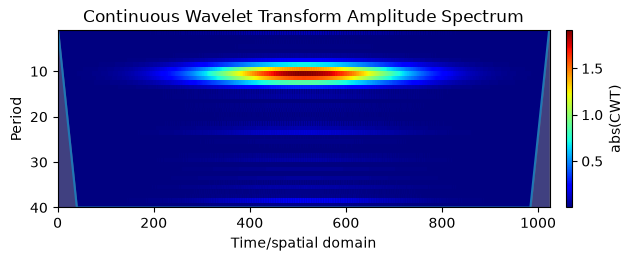

In [216]:
# Temporary compatibility shim for legacy code
if not hasattr(np, "int"):
    np.int = int



In [278]:
# choose default wavelet function for the entire notebook
scg.set_default_wavelet('cmor1-1.5')

# Try these ones to see various compromises between scales and time resolution 
#scg.set_default_wavelet('cgau5')
#scg.set_default_wavelet('cgau1')
#scg.set_default_wavelet('shan0.5-2')
#scg.set_default_wavelet('mexh')

Default wavelet function used to compute the transform: cmor1-1.5 ( Complex Morlet wavelets )


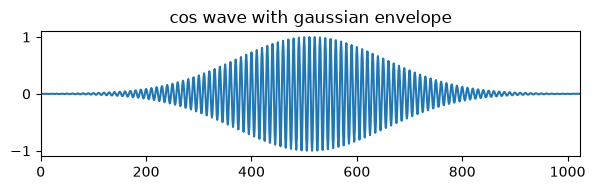

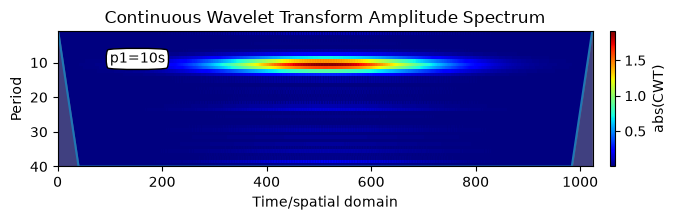

In [279]:
# let consider a timeline with 1 sample / second
ns   = 1024
time = np.arange(ns)

# and a range of scales to perform the transform
scales = scg.periods2scales( np.arange(1, 40) )

# and a periodic signal with varying amplitude
p1=10; periodic1 = np.cos(2*np.pi/p1*time) * np.exp(-((time-ns/2)/200)**2)

# plot the signal 
fig1, ax1 = plt.subplots(1, 1, figsize=(6.2,2));  
lines = ax1.plot(periodic1); 
ax1.set_xlim(0, len(time))
ax1.set_title("cos wave with gaussian envelope")
fig1.tight_layout()

# and the scaleogram
#ax2 = scg.cws(periodic1, scales=scales, figsize=(6.9,2.3)); 
ax2 = scg.cws(
    periodic1,
    scales=scales,
    figsize=(6.9, 2.3),
    coikw={"alpha": 0.5, "color": "gray"}
)
txt = ax2.annotate("p1=10s", xy=(100, 10), bbox=dict(boxstyle="round4", fc="w"))
plt.tight_layout()

print("Default wavelet function used to compute the transform:", scg.get_default_wavelet(), "(",
      pywt.ContinuousWavelet(scg.get_default_wavelet()).family_name, ")")

In [280]:
print(periodic1)
print(time)
print(scales)

[ 0.00142498  0.00118269  0.00046343 ...  0.00124458  0.00046343
 -0.00045175]
[   0    1    2 ... 1021 1022 1023]
[ 1.5  3.   4.5  6.   7.5  9.  10.5 12.  13.5 15.  16.5 18.  19.5 21.
 22.5 24.  25.5 27.  28.5 30.  31.5 33.  34.5 36.  37.5 39.  40.5 42.
 43.5 45.  46.5 48.  49.5 51.  52.5 54.  55.5 57.  58.5]


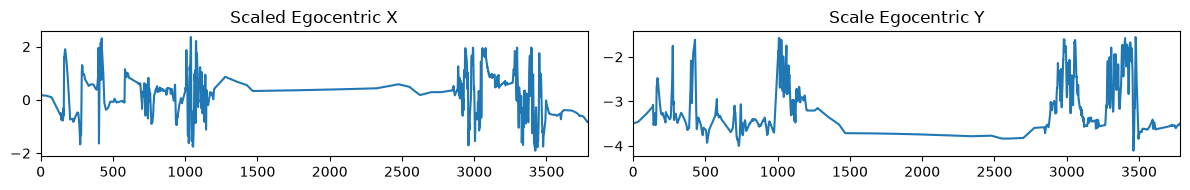

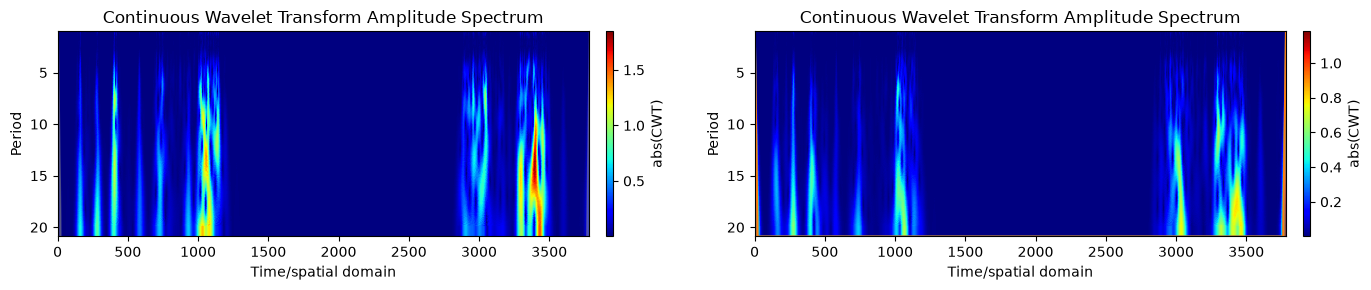

In [281]:
### test our data 
time = df_x["time"]
#scales = scg.periods2scales( np.arange(1, 50) )
signal_x = df_x["position"]
signal_y = df_y["position"]
# and a periodic signal with varying amplitude
#p1=10; periodic1 = np.cos(2*np.pi/p1*time) * np.exp(-((time-ns/2)/200)**2)

# plot the signal 
# plot the pulses
fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 2)); 

ax1.set_title("Scaled Egocentric X"); ax2.set_title("Scale Egocentric Y")
lines = ax1.plot(signal_x); ax1.set_xlim(0, len(time))
lines = ax2.plot(signal_y); ax2.set_xlim(0, len(time))
fig1.tight_layout()

# and the scaleogram
scales = scg.periods2scales(np.arange(1, 20, 0.1) )
fig2, (ax3, ax4) = plt.subplots(1, 2, figsize=(14,3));

ax3 = scg.cws(signal_x, scales=scales, ax=ax3, figsize=(6.9, 2.3),
    coikw={"alpha": 0.5, "color": "gray"})
ax4 = scg.cws(signal_y, scales=scales, ax=ax4, figsize=(6.9, 2.3),
    coikw={"alpha": 0.5, "color": "gray"})
#for bmpw, stepw in [(2*s1, 2*w1), (2*s2,2*w2), (2*s3, 2*w3)]:
#    ax3.plot(ax3.get_xlim(), bmpw*np.ones(2), 'w-', alpha=0.5)
#    ax4.plot(ax4.get_xlim(), stepw*np.ones(2), 'w-', alpha=0.5)
fig2.tight_layout()

       time  position
0  0.000000  0.172016
1  0.033333  0.171796
2  0.066667  0.171577
3  0.100000  0.171358
4  0.133333  0.171140
       time  position
0  0.000000 -3.496464
1  0.033333 -3.495405
2  0.066667 -3.494346
3  0.100000 -3.493287
4  0.133333 -3.492229


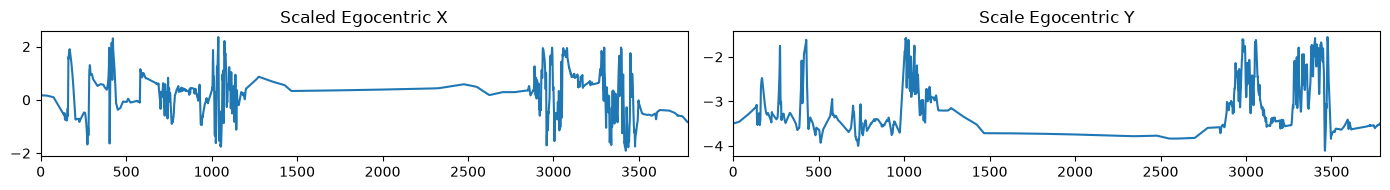

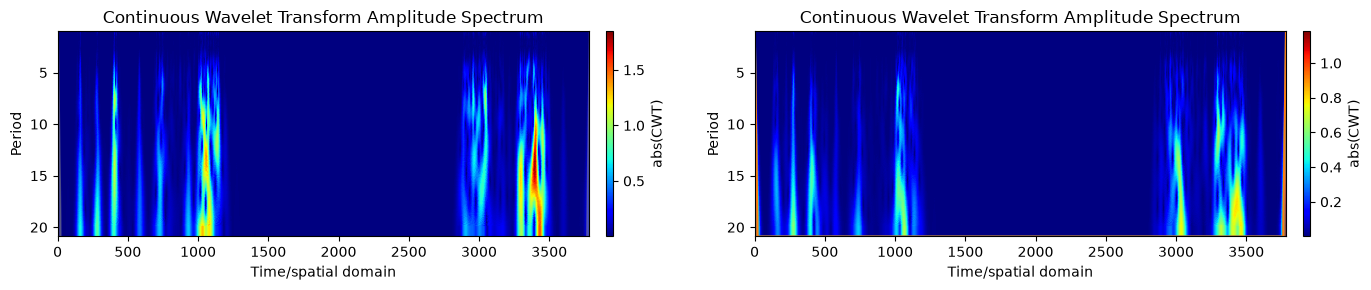

In [282]:
sacled_position = ds["position_scaled"].sel(keypoints="tail_tip", individuals="id_0")   # dims: (time, space)
df_x = pd.DataFrame({
    "time": snout["time"].values,
    "position": sacled_position.sel(space="x").values,
})

df_y = pd.DataFrame({
    "time": snout["time"].values,
    "position": sacled_position.sel(space="y").values,
})

print(df_x.head())
print(df_y.head())
### test our data 
time = df_x["time"]
#scales = scg.periods2scales( np.arange(1, 50) )
signal_x = df_x["position"]
signal_y = df_y["position"]
# and a periodic signal with varying amplitude
#p1=10; periodic1 = np.cos(2*np.pi/p1*time) * np.exp(-((time-ns/2)/200)**2)

# plot the signal 
# plot the pulses
fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 2)); 

ax1.set_title("Scaled Egocentric X"); ax2.set_title("Scale Egocentric Y")
lines = ax1.plot(signal_x); ax1.set_xlim(0, len(time))
lines = ax2.plot(signal_y); ax2.set_xlim(0, len(time))
fig1.tight_layout()

# and the scaleogram
#scales = scg.periods2scales(np.arange(1, 10, 0.1) )
fig2, (ax3, ax4) = plt.subplots(1, 2, figsize=(14,3));

ax3 = scg.cws(signal_x, scales=scales, ax=ax3, figsize=(6.9, 2.3),
    coikw={"alpha": 0.5, "color": "gray"})
ax4 = scg.cws(signal_y, scales=scales, ax=ax4, figsize=(6.9, 2.3),
    coikw={"alpha": 0.5, "color": "gray"})
#for bmpw, stepw in [(2*s1, 2*w1), (2*s2,2*w2), (2*s3, 2*w3)]:
#    ax3.plot(ax3.get_xlim(), bmpw*np.ones(2), 'w-', alpha=0.5)
#    ax4.plot(ax4.get_xlim(), stepw*np.ones(2), 'w-', alpha=0.5)
fig2.tight_layout()

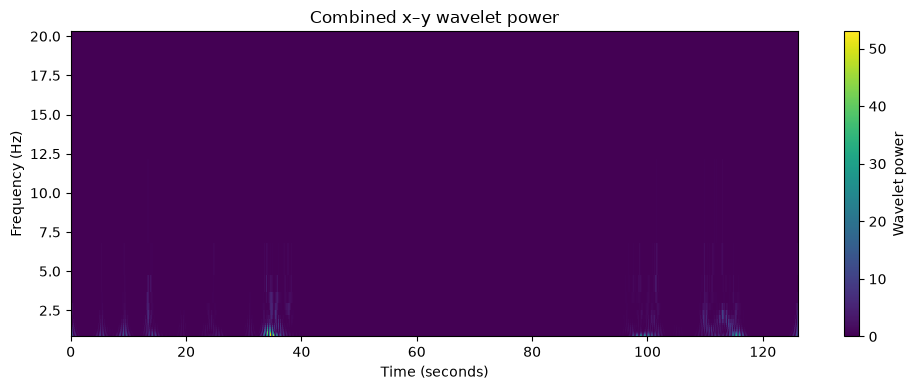

In [289]:
### test combine x and y
import pywt
fs = 30
scales = scg.periods2scales(np.arange(1, 20, 1) )
coef_x, frequencies = pywt.cwt(
    signal_x, 
    scales,
    "morl",
    sampling_period=1 / fs,
)

coef_y, _ = pywt.cwt(
    signal_y,
    scales,
    "morl",
    sampling_period=1 / fs,
)

power_xy = np.abs(coef_x)**2 + np.abs(coef_y)**2

fig, ax = plt.subplots(figsize=(10, 4))
mesh = ax.pcolormesh(
    time,
    frequencies,
    power_xy,
    shading="auto",
)
#ax.set_yscale("log")
ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Frequency (Hz)")
ax.set_title("Combined x–y wavelet power")
fig.colorbar(mesh, ax=ax, label="Wavelet power")
plt.tight_layout()
